## Instalacion de bibliotecas y lectura de la base de datos


In [ ]:
!pip install pandas 
!pip install numpy 
!pip install sympy 
!pip install matplotlib.pyplot
!pip install seaborn

In [7]:
import pandas as pd
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("../datos/bmw.csv", sep=";")

## Punto 2


In [8]:
#Correcion de Tamano del motor y limpieza del precio
df['price'] = df['price'].astype(str).str.replace('$', '', regex=False).str.replace('.', '', regex=False).astype(float)
df['engineSize'] = df['engineSize'] / 10.0

In [ ]:
# confirmacion de que no hay valores nulos ni repetidos 
df.isnull().sum()
df.duplicated().sum()

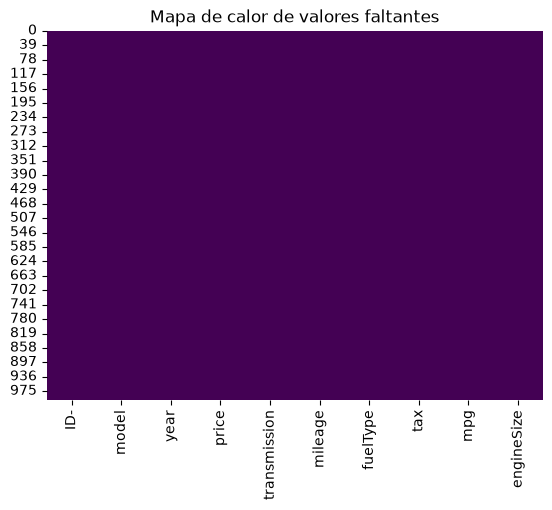

In [12]:
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title("Mapa de calor de valores faltantes")
plt.show()


### **Justificación Ítem 2:** Tras revisar la matriz y el mapa de calor, se confirma que el conjunto de datos no presenta valores faltantes (0 nulos en todas las columnas), por lo que no es necesario realizar procesos de imputación ni eliminación de registros.

## Punto 4


In [14]:
df['model'] = df['model'].astype(str).str.strip()
df['transmission'] = df['transmission'].astype(str).str.strip()
df['fuelType'] = df['fuelType'].astype(str).str.strip()
df = df.drop_duplicates()

### **Conclusión Ítem 4:** Se normalizaron las variables categóricas de texto (`model`, `transmission`, `fuelType`) eliminando espacios en blanco innecesarios. Posteriormente se identificaron y eliminaron los registros duplicados en el conjunto de datos para garantizar la consistencia del análisis.

## Punto 6 

In [17]:
r1 = df[(df['transmission'] == 'Automatic') & (df['price'] > 50000)].shape[0]
r2 = df[(df['year'] == 2020) & (df['mileage'] < 5000)].shape[0]
r3 = df[df['engineSize'] >= 3.0].shape[0]
r4 = df[(df['fuelType'] == 'Diesel') & (df['model'] == '1 Series')].shape[0]
r5 = df[df['price'] < 10000].shape[0]

print("1. Autos automaticos de mas de $50,000:", r1)
print("2. Autos 2020 con menos de 5,000 millas:", r2)
print("3. Autos con motor de 3.0L o superior:", r3)
print("4. Autos Serie 1 con motor Diesel:", r4)
print("5. Autos economicos por debajo de $10,000:", r5)

1. Autos automaticos de mas de $50,000: 12
2. Autos 2020 con menos de 5,000 millas: 63
3. Autos con motor de 3.0L o superior: 240
4. Autos Serie 1 con motor Diesel: 108
5. Autos economicos por debajo de $10,000: 77


### Conclusiones Ítem 6
1. Los vehículos automáticos de gama alta (> $50k) representan un segmento exclusivo del catálogo.
2. Existen unidades del año 2020 prácticamente nuevas con muy bajo kilometraje disponible.
3. Los motores de alto cilindraje (>= 3.0L) son una minoría dentro de la oferta de la marca.
4. El modelo Serie 1 cuenta con una presencia importante de variantes diésel de bajo consumo.
5. La oferta de vehículos accesibles por debajo de $10,000 es reducida y corresponde a modelos de mayor antigüedad.